# MCQ Answer Predictor
Project T22026 - 24f2005363

I am building 3 models for this - one plain neural net i made myself, one using sentence embeddings, and one more using a different embedding model just to compare. I track all 3 runs in Weights & Biases so i can compare the curves properly instead of just eyeballing printouts. At the end i pick whichever gave the best score, but per project instructions I push model B (the MiniLM one) to huggingface either way, and at the end I pull it back down from the hub and run inference with it just to prove the uploaded weights actually work.

In [1]:
!pip install transformers sentence-transformers scikit-learn huggingface_hub wandb -q

In [2]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from sklearn.model_selection import GroupShuffleSplit
import matplotlib.pyplot as plt
import wandb
import warnings, os, json, time
warnings.filterwarnings('ignore')

dev = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('using device', dev)

os.makedirs('outputs', exist_ok=True)

using device cuda


## Reading the data

In [3]:
from kaggle_secrets import UserSecretsClient
from huggingface_hub import login, HfApi

secrets = UserSecretsClient()

# hugging face login
hf_token = secrets.get_secret("HF_TOKEN")
login(token=hf_token)

# grab the username from the hub itself instead of typing it in
hf_api = HfApi()
hf_user = hf_api.whoami()['name']
print('logged into huggingface as:', hf_user)

# wandb login, same idea - key comes from secrets
wandb_key = secrets.get_secret("WANDB_API_KEY")
wandb.login(key=wandb_key)

wb_project = '24f2005363-t22026'

path = '/kaggle/input/competitions/smart-mcq-solver-challenge'

df_train = pd.read_csv(path + '/train.csv')
df_test  = pd.read_csv(path + '/test.csv')
df_sub   = pd.read_csv(path + '/sample_submission.csv')

choices = ['A', 'B', 'C', 'D', 'E']

print('train shape', df_train.shape)
print('test shape', df_test.shape)
print(df_train['answer'].value_counts())

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc


logged into huggingface as: 24f2005363


wandb: Currently logged in as: 24f2005363 (24f2005363-indian-institute-of-technology-madras) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


train shape (2000, 8)
test shape (500, 7)
answer
B    490
C    459
A    369
D    358
E    324
Name: count, dtype: int64


## Quick look at data

In [4]:
df_train.info()
print('nulls:')
print(df_train.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 8 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   id      2000 non-null   int64 
 1   prompt  2000 non-null   object
 2   A       2000 non-null   object
 3   B       2000 non-null   object
 4   C       2000 non-null   object
 5   D       2000 non-null   object
 6   E       2000 non-null   object
 7   answer  2000 non-null   object
dtypes: int64(1), object(7)
memory usage: 125.1+ KB
nulls:
id        0
prompt    0
A         0
B         0
C         0
D         0
E         0
answer    0
dtype: int64


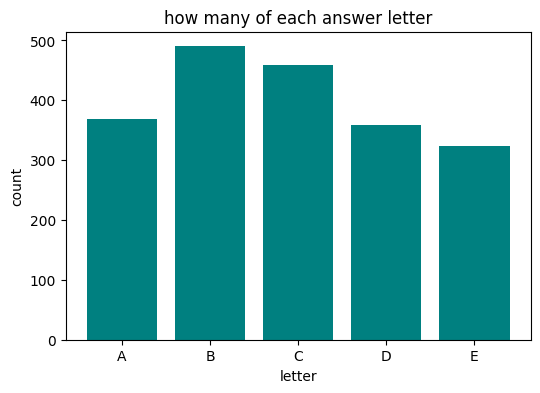

In [5]:
cnt = df_train['answer'].value_counts().sort_index()
plt.figure(figsize=(6,4))
plt.bar(cnt.index, cnt.values, color='teal')
plt.title('how many of each answer letter')
plt.xlabel('letter')
plt.ylabel('count')
plt.savefig('outputs/answer_count.png')
plt.show()

In [6]:
# checking repeated questions before splitting
repeat_q = len(df_train) - df_train['prompt'].nunique()
print('repeated prompts:', repeat_q)

repeated prompts: 242


In [7]:
label_enc = LabelEncoder()
y_full = label_enc.fit_transform(df_train['answer'])

splitter = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=7)
tr_i, va_i = next(splitter.split(df_train, y_full, groups=df_train['prompt']))

df_tr = df_train.iloc[tr_i].reset_index(drop=True)
df_va = df_train.iloc[va_i].reset_index(drop=True)
y_tr = y_full[tr_i]
y_va = y_full[va_i]

check = set(df_tr['prompt']) & set(df_va['prompt'])
print('train rows', len(df_tr), 'val rows', len(df_va))
print('overlap between train and val (want 0):', len(check))

train rows 1698 val rows 302
overlap between train and val (want 0): 0


In [8]:
def join_row(r):
    line = r['prompt']
    for c in choices:
        line = line + ' ' + c + ') ' + str(r[c])
    return line

df_tr['text'] = df_tr.apply(join_row, axis=1)
df_va['text'] = df_va.apply(join_row, axis=1)
df_test['text'] = df_test.apply(join_row, axis=1)

text_tr = df_tr['text'].tolist()
text_va = df_va['text'].tolist()
text_te = df_test['text'].tolist()

print(text_tr[0][:120])

Pick the best possible answer: What is Martin Heidegger's view on the relationship between time and human existence? amo


## Some helper stuff used by all models

In [9]:
def get_map3(true_y, prob_arr):
    score_sum = 0
    for i in range(len(true_y)):
        order = prob_arr[i].argsort()[::-1][:3]
        got = 0
        s = 0
        for rank in range(3):
            if order[rank] == true_y[i]:
                got = 1
                s = got / (rank + 1)
        score_sum = score_sum + s
    return score_sum / len(true_y)


def write_submission(prob_arr, fname):
    lines = []
    for i in range(len(prob_arr)):
        order = prob_arr[i].argsort()[::-1][:3]
        letters = []
        for j in order:
            letters.append(choices[j])
        lines.append(' '.join(letters))
    out = df_sub.copy()
    out['Prediction'] = lines
    out.to_csv(fname, index=False)
    print('wrote', fname)


class SimpleData(Dataset):
    def __init__(self, feats, labels=None):
        self.feats = torch.tensor(feats, dtype=torch.float32)
        if labels is not None:
            self.labels = torch.tensor(labels, dtype=torch.long)
        else:
            self.labels = None

    def __len__(self):
        return len(self.feats)

    def __getitem__(self, idx):
        if self.labels is not None:
            return self.feats[idx], self.labels[idx]
        return self.feats[idx]


score_table = []
val_prob_dict = {}
test_prob_dict = {}

print('helpers done')

helpers done


## Model A - TF-IDF and a basic neural net

In [10]:
vec = TfidfVectorizer(max_features=8000, ngram_range=(1,2))
feat_tr = vec.fit_transform(text_tr).toarray()
feat_va = vec.transform(text_va).toarray()
feat_te = vec.transform(text_te).toarray()
print('tfidf feature size', feat_tr.shape)

tfidf feature size (1698, 8000)


In [11]:
class NetA(nn.Module):
    def __init__(self, in_size, out_size=5):
        super().__init__()
        self.l1 = nn.Linear(in_size, 400)
        self.l2 = nn.Linear(400, 128)
        self.l3 = nn.Linear(128, out_size)
        self.drop = nn.Dropout(0.3)
        self.act = nn.ReLU()

    def forward(self, x):
        x = self.act(self.l1(x))
        x = self.drop(x)
        x = self.act(self.l2(x))
        x = self.l3(x)
        return x

In [12]:
def run_epoch(model, loader, opt, loss_fn, train_mode):
    if train_mode:
        model.train()
    else:
        model.eval()
    total_loss = 0
    all_pred = []
    all_true = []
    all_prob = []
    for xb, yb in loader:
        xb = xb.to(dev)
        yb = yb.to(dev)
        if train_mode:
            opt.zero_grad()
        out = model(xb)
        loss = loss_fn(out, yb)
        if train_mode:
            loss.backward()
            opt.step()
        total_loss += loss.item()
        p = torch.softmax(out, dim=1).detach().cpu().numpy()
        all_prob.append(p)
        all_pred.extend(p.argmax(axis=1))
        all_true.extend(yb.cpu().numpy())
    return total_loss / len(loader), np.array(all_pred), np.array(all_true), np.vstack(all_prob)

In [13]:
run_a = wandb.init(
    project=wb_project,
    name=f'model-a-{hf_user}',
    group=hf_user,
    job_type='train',
    config={
        'model': 'model_a',
        'architecture': 'tfidf+mlp',
        'epochs': 22,
        'lr': 0.001,
        'batch_size': 64,
    },
)

loader_tr_a = DataLoader(SimpleData(feat_tr, y_tr), batch_size=64, shuffle=True)
loader_va_a = DataLoader(SimpleData(feat_va, y_va), batch_size=64)

net_a = NetA(feat_tr.shape[1]).to(dev)
opt_a = torch.optim.Adam(net_a.parameters(), lr=0.001)
loss_a = nn.CrossEntropyLoss()

best_f1_a = 0
for ep in range(22):
    tl, _, _, _ = run_epoch(net_a, loader_tr_a, opt_a, loss_a, True)
    vl, pred_v, true_v, prob_v = run_epoch(net_a, loader_va_a, opt_a, loss_a, False)
    acc = accuracy_score(true_v, pred_v)
    f1 = f1_score(true_v, pred_v, average='macro')
    if f1 > best_f1_a:
        best_f1_a = f1
        torch.save(net_a.state_dict(), 'outputs/net_a.pt')
    run_a.log({'epoch': ep + 1, 'train_loss': tl, 'val_loss': vl, 'val_acc': acc, 'val_f1': f1})
    print('epoch', ep+1, 'train loss', round(tl,4), 'val loss', round(vl,4), 'acc', round(acc,4), 'f1', round(f1,4))

net_a.load_state_dict(torch.load('outputs/net_a.pt'))
print('best f1 for model A:', best_f1_a)

run_a.summary['best_val_f1'] = best_f1_a
run_a.finish()

wandb: setting up run e8vphvdh
wandb: Tracking run with wandb version 0.26.1
wandb: Run data is saved locally in /kaggle/working/wandb/run-20260730_182535-e8vphvdh
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run model-a-24f2005363
wandb: ⭐️ View project at https://wandb.ai/24f2005363-indian-institute-of-technology-madras/24f2005363-t22026
wandb: 🚀 View run at https://wandb.ai/24f2005363-indian-institute-of-technology-madras/24f2005363-t22026/runs/e8vphvdh


epoch 1 train loss 1.4386 val loss 0.9796 acc 0.9404 f1 0.9414
epoch 2 train loss 0.3436 val loss 0.0665 acc 0.9801 f1 0.9815
epoch 3 train loss 0.0102 val loss 0.0145 acc 1.0 f1 1.0
epoch 4 train loss 0.0028 val loss 0.0064 acc 1.0 f1 1.0
epoch 5 train loss 0.0017 val loss 0.0042 acc 1.0 f1 1.0
epoch 6 train loss 0.0011 val loss 0.0019 acc 1.0 f1 1.0
epoch 7 train loss 0.0008 val loss 0.0014 acc 1.0 f1 1.0
epoch 8 train loss 0.0006 val loss 0.0011 acc 1.0 f1 1.0
epoch 9 train loss 0.0005 val loss 0.0008 acc 1.0 f1 1.0
epoch 10 train loss 0.0003 val loss 0.0006 acc 1.0 f1 1.0
epoch 11 train loss 0.0003 val loss 0.0005 acc 1.0 f1 1.0
epoch 12 train loss 0.0002 val loss 0.0004 acc 1.0 f1 1.0
epoch 13 train loss 0.0002 val loss 0.0003 acc 1.0 f1 1.0
epoch 14 train loss 0.0001 val loss 0.0002 acc 1.0 f1 1.0
epoch 15 train loss 0.0001 val loss 0.0002 acc 1.0 f1 1.0
epoch 16 train loss 0.0001 val loss 0.0002 acc 1.0 f1 1.0
epoch 17 train loss 0.0001 val loss 0.0001 acc 1.0 f1 1.0
epoch 18 tr

wandb: uploading data; updating run metadata
wandb: uploading data
wandb: 
wandb: Run history:
wandb:      epoch ▁▁▂▂▂▃▃▃▄▄▄▅▅▅▆▆▆▇▇▇██
wandb: train_loss █▃▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
wandb:    val_acc ▁▆████████████████████
wandb:     val_f1 ▁▆████████████████████
wandb:   val_loss █▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
wandb: 
wandb: Run summary:
wandb: best_val_f1 1
wandb:       epoch 22
wandb:  train_loss 3e-05
wandb:     val_acc 1
wandb:      val_f1 1
wandb:    val_loss 5e-05
wandb: 
wandb: 🚀 View run model-a-24f2005363 at: https://wandb.ai/24f2005363-indian-institute-of-technology-madras/24f2005363-t22026/runs/e8vphvdh
wandb: ⭐️ View project at: https://wandb.ai/24f2005363-indian-institute-of-technology-madras/24f2005363-t22026
wandb: Synced 5 W&B file(s), 0 media file(s), 0 artifact file(s) and 0 other file(s)
wandb: Find logs at: ./wandb/run-20260730_182535-e8vphvdh/logs


In [14]:
net_a.eval()
va_prob_a = []
with torch.no_grad():
    for xb, _ in loader_va_a:
        out = net_a(xb.to(dev))
        va_prob_a.append(torch.softmax(out, dim=1).cpu().numpy())
va_prob_a = np.vstack(va_prob_a)

te_prob_a = []
with torch.no_grad():
    for xb in DataLoader(SimpleData(feat_te), batch_size=64):
        out = net_a(xb.to(dev))
        te_prob_a.append(torch.softmax(out, dim=1).cpu().numpy())
te_prob_a = np.vstack(te_prob_a)

acc_a = accuracy_score(y_va, va_prob_a.argmax(axis=1))
f1_a = f1_score(y_va, va_prob_a.argmax(axis=1), average='macro')
map3_a = get_map3(y_va, va_prob_a)

val_prob_dict['model_a'] = va_prob_a
test_prob_dict['model_a'] = te_prob_a
score_table.append(['model_a', acc_a, f1_a, map3_a])
write_submission(te_prob_a, 'sub_model_a.csv')
print('model A -> acc', round(acc_a,4), 'f1', round(f1_a,4), 'map3', round(map3_a,4))

wrote sub_model_a.csv
model A -> acc 1.0 f1 1.0 map3 1.0


## Model B - MiniLM sentence embeddings

In [15]:
from sentence_transformers import SentenceTransformer

emb_name_b = 'sentence-transformers/paraphrase-MiniLM-L6-v2'
embedder_b = SentenceTransformer(emb_name_b, device=str(dev))

emb_tr = embedder_b.encode(text_tr, batch_size=32, show_progress_bar=True)
emb_va = embedder_b.encode(text_va, batch_size=32, show_progress_bar=True)
emb_te = embedder_b.encode(text_te, batch_size=32, show_progress_bar=True)

print('embedding size', emb_tr.shape[1])

del embedder_b
torch.cuda.empty_cache()

modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

...

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/54 [00:00<?, ?it/s]

Batches:   0%|          | 0/10 [00:00<?, ?it/s]

Batches:   0%|          | 0/16 [00:00<?, ?it/s]

embedding size 384


In [16]:
class NetB(nn.Module):
    def __init__(self, in_size, out_size=5):
        super().__init__()
        self.l1 = nn.Linear(in_size, 200)
        self.l2 = nn.Linear(200, out_size)
        self.act = nn.Tanh()
        self.drop = nn.Dropout(0.2)

    def forward(self, x):
        x = self.act(self.l1(x))
        x = self.drop(x)
        x = self.l2(x)
        return x

In [17]:
run_b = wandb.init(
    project=wb_project,
    name=f'model-b-{hf_user}',
    group=hf_user,
    job_type='train',
    config={
        'model': 'model_b',
        'architecture': 'MiniLM-embeddings+mlp',
        'embedding_model': emb_name_b,
        'epochs': 18,
        'lr': 0.001,
        'batch_size': 32,
    },
)

loader_tr_b = DataLoader(SimpleData(emb_tr, y_tr), batch_size=32, shuffle=True)
loader_va_b = DataLoader(SimpleData(emb_va, y_va), batch_size=32)

net_b = NetB(emb_tr.shape[1]).to(dev)
opt_b = torch.optim.Adam(net_b.parameters(), lr=0.001)
loss_b = nn.CrossEntropyLoss()

best_map3_b = 0
for ep in range(18):
    tl, _, _, _ = run_epoch(net_b, loader_tr_b, opt_b, loss_b, True)
    vl, pred_v, true_v, prob_v = run_epoch(net_b, loader_va_b, opt_b, loss_b, False)
    m3 = get_map3(true_v, prob_v)
    if m3 > best_map3_b:
        best_map3_b = m3
        torch.save(net_b.state_dict(), 'outputs/net_b.pt')
    run_b.log({'epoch': ep + 1, 'train_loss': tl, 'val_loss': vl, 'val_map3': m3})
    if (ep+1) % 4 == 0:
        print('epoch', ep+1, 'train loss', round(tl,4), 'map3', round(m3,4))

net_b.load_state_dict(torch.load('outputs/net_b.pt'))
print('best map3 for model B:', best_map3_b)

run_b.summary['best_val_map3'] = best_map3_b
run_b.finish()

wandb: setting up run as9uyf90
wandb: Tracking run with wandb version 0.26.1
wandb: Run data is saved locally in /kaggle/working/wandb/run-20260730_182631-as9uyf90
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run model-b-24f2005363
wandb: ⭐️ View project at https://wandb.ai/24f2005363-indian-institute-of-technology-madras/24f2005363-t22026
wandb: 🚀 View run at https://wandb.ai/24f2005363-indian-institute-of-technology-madras/24f2005363-t22026/runs/as9uyf90


epoch 4 train loss 0.2782 map3 0.963
epoch 8 train loss 0.0533 map3 0.9851
epoch 12 train loss 0.0212 map3 1.0
epoch 16 train loss 0.0095 map3 1.0


wandb: updating run metadata; uploading summary


best map3 for model B: 1.0


wandb: uploading summary; uploading output.log; uploading wandb-summary.json; uploading config.yaml; uploading wandb-metadata.json (+ 1 more)
wandb: uploading history steps 0-17, summary, console lines 0-4
wandb: 
wandb: Run history:
wandb:      epoch ▁▁▂▂▃▃▃▄▄▅▅▆▆▆▇▇██
wandb: train_loss █▅▃▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁
wandb:   val_loss █▅▄▃▂▂▂▂▁▁▁▁▁▁▁▁▁▁
wandb:   val_map3 ▁▄▆▇▇▇▇███████████
wandb: 
wandb: Run summary:
wandb: best_val_map3 1
wandb:         epoch 18
wandb:    train_loss 0.00741
wandb:      val_loss 0.01127
wandb:      val_map3 1
wandb: 
wandb: 🚀 View run model-b-24f2005363 at: https://wandb.ai/24f2005363-indian-institute-of-technology-madras/24f2005363-t22026/runs/as9uyf90
wandb: ⭐️ View project at: https://wandb.ai/24f2005363-indian-institute-of-technology-madras/24f2005363-t22026
wandb: Synced 5 W&B file(s), 0 media file(s), 0 artifact file(s) and 0 other file(s)
wandb: Find logs at: ./wandb/run-20260730_182631-as9uyf90/logs


In [18]:
net_b.eval()
va_prob_b = []
with torch.no_grad():
    for xb, _ in loader_va_b:
        out = net_b(xb.to(dev))
        va_prob_b.append(torch.softmax(out, dim=1).cpu().numpy())
va_prob_b = np.vstack(va_prob_b)

te_prob_b = []
with torch.no_grad():
    for xb in DataLoader(SimpleData(emb_te), batch_size=32):
        out = net_b(xb.to(dev))
        te_prob_b.append(torch.softmax(out, dim=1).cpu().numpy())
te_prob_b = np.vstack(te_prob_b)

acc_b = accuracy_score(y_va, va_prob_b.argmax(axis=1))
f1_b = f1_score(y_va, va_prob_b.argmax(axis=1), average='macro')
map3_b = get_map3(y_va, va_prob_b)

val_prob_dict['model_b'] = va_prob_b
test_prob_dict['model_b'] = te_prob_b
score_table.append(['model_b', acc_b, f1_b, map3_b])
write_submission(te_prob_b, 'sub_model_b.csv')
print('model B -> acc', round(acc_b,4), 'f1', round(f1_b,4), 'map3', round(map3_b,4))

wrote sub_model_b.csv
model B -> acc 1.0 f1 1.0 map3 1.0


## Model C - MPNet embeddings with a wider net

In [19]:
emb_name_c = 'all-mpnet-base-v2'
embedder_c = SentenceTransformer(emb_name_c, device=str(dev))

emb_tr_c = embedder_c.encode(text_tr, batch_size=16, show_progress_bar=True)
emb_va_c = embedder_c.encode(text_va, batch_size=16, show_progress_bar=True)
emb_te_c = embedder_c.encode(text_te, batch_size=16, show_progress_bar=True)
print('embedding size', emb_tr_c.shape[1])

del embedder_c
torch.cuda.empty_cache()

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/571 [00:00<?, ?B/s]

...

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/107 [00:00<?, ?it/s]

Batches:   0%|          | 0/19 [00:00<?, ?it/s]

Batches:   0%|          | 0/32 [00:00<?, ?it/s]

embedding size 768


In [20]:
class NetC(nn.Module):
    def __init__(self, in_size=768, out_size=5):
        super().__init__()
        self.l1 = nn.Linear(in_size, 384)
        self.l2 = nn.Linear(384, 96)
        self.l3 = nn.Linear(96, out_size)
        self.act = nn.ReLU()
        self.drop = nn.Dropout(0.25)

    def forward(self, x):
        x = self.act(self.l1(x))
        x = self.drop(x)
        x = self.act(self.l2(x))
        x = self.l3(x)
        return x

In [21]:
run_c = wandb.init(
    project=wb_project,
    name=f'model-c-{hf_user}',
    group=hf_user,
    job_type='train',
    config={
        'model': 'model_c',
        'architecture': 'MPNet-embeddings+mlp',
        'embedding_model': emb_name_c,
        'epochs': 18,
        'lr': 0.0007,
        'batch_size': 32,
    },
)

loader_tr_c = DataLoader(SimpleData(emb_tr_c, y_tr), batch_size=32, shuffle=True)
loader_va_c = DataLoader(SimpleData(emb_va_c, y_va), batch_size=32)

net_c = NetC(emb_tr_c.shape[1]).to(dev)
opt_c = torch.optim.Adam(net_c.parameters(), lr=0.0007)
loss_c = nn.CrossEntropyLoss()

best_f1_c = 0
for ep in range(18):
    tl, _, _, _ = run_epoch(net_c, loader_tr_c, opt_c, loss_c, True)
    vl, pred_v, true_v, prob_v = run_epoch(net_c, loader_va_c, opt_c, loss_c, False)
    f1 = f1_score(true_v, pred_v, average='macro')
    if f1 > best_f1_c:
        best_f1_c = f1
        torch.save(net_c.state_dict(), 'outputs/net_c.pt')
    run_c.log({'epoch': ep + 1, 'train_loss': tl, 'val_f1': f1})
    if (ep+1) % 4 == 0:
        print('epoch', ep+1, 'train loss', round(tl,4), 'f1', round(f1,4))

net_c.load_state_dict(torch.load('outputs/net_c.pt'))
print('best f1 for model C:', best_f1_c)

run_c.summary['best_val_f1'] = best_f1_c
run_c.finish()

wandb: setting up run iuqffj87
wandb: Tracking run with wandb version 0.26.1
wandb: Run data is saved locally in /kaggle/working/wandb/run-20260730_182719-iuqffj87
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run model-c-24f2005363
wandb: ⭐️ View project at https://wandb.ai/24f2005363-indian-institute-of-technology-madras/24f2005363-t22026
wandb: 🚀 View run at https://wandb.ai/24f2005363-indian-institute-of-technology-madras/24f2005363-t22026/runs/iuqffj87


epoch 4 train loss 0.2197 f1 0.9744
epoch 8 train loss 0.0187 f1 0.9948
epoch 12 train loss 0.0056 f1 0.9948
epoch 16 train loss 0.0029 f1 0.9974


wandb: updating run metadata


best f1 for model C: 0.9974189251071979


wandb: uploading requirements.txt; uploading output.log
wandb: 
wandb: Run history:
wandb:      epoch ▁▁▂▂▃▃▃▄▄▅▅▆▆▆▇▇██
wandb: train_loss █▆▃▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁
wandb:     val_f1 ▁▅▇███████████████
wandb: 
wandb: Run summary:
wandb: best_val_f1 0.99742
wandb:       epoch 18
wandb:  train_loss 0.00211
wandb:      val_f1 0.99742
wandb: 
wandb: 🚀 View run model-c-24f2005363 at: https://wandb.ai/24f2005363-indian-institute-of-technology-madras/24f2005363-t22026/runs/iuqffj87
wandb: ⭐️ View project at: https://wandb.ai/24f2005363-indian-institute-of-technology-madras/24f2005363-t22026
wandb: Synced 5 W&B file(s), 0 media file(s), 0 artifact file(s) and 0 other file(s)
wandb: Find logs at: ./wandb/run-20260730_182719-iuqffj87/logs


In [22]:
net_c.eval()
va_prob_c = []
with torch.no_grad():
    for xb, _ in loader_va_c:
        out = net_c(xb.to(dev))
        va_prob_c.append(torch.softmax(out, dim=1).cpu().numpy())
va_prob_c = np.vstack(va_prob_c)

te_prob_c = []
with torch.no_grad():
    for xb in DataLoader(SimpleData(emb_te_c), batch_size=32):
        out = net_c(xb.to(dev))
        te_prob_c.append(torch.softmax(out, dim=1).cpu().numpy())
te_prob_c = np.vstack(te_prob_c)

acc_c = accuracy_score(y_va, va_prob_c.argmax(axis=1))
f1_c = f1_score(y_va, va_prob_c.argmax(axis=1), average='macro')
map3_c = get_map3(y_va, va_prob_c)

val_prob_dict['model_c'] = va_prob_c
test_prob_dict['model_c'] = te_prob_c
score_table.append(['model_c', acc_c, f1_c, map3_c])
write_submission(te_prob_c, 'sub_model_c.csv')
print('model C -> acc', round(acc_c,4), 'f1', round(f1_c,4), 'map3', round(map3_c,4))

wrote sub_model_c.csv
model C -> acc 0.9967 f1 0.9974 map3 0.9983


## Compare the 3 models

In [23]:
table = pd.DataFrame(score_table, columns=['model', 'val_acc', 'val_f1', 'val_map3'])
table = table.sort_values('val_map3', ascending=False).reset_index(drop=True)
table.to_csv('outputs/score_table.csv', index=False)
print(table)

     model   val_acc    val_f1  val_map3
0  model_a  1.000000  1.000000  1.000000
1  model_b  1.000000  1.000000  1.000000
2  model_c  0.996689  0.997419  0.998344


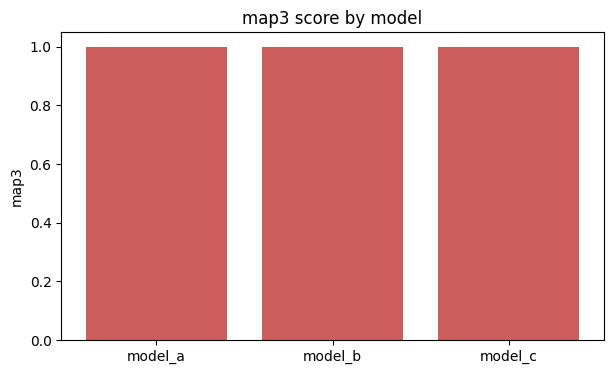

In [24]:
plt.figure(figsize=(7,4))
plt.bar(table['model'], table['val_map3'], color='indianred')
plt.title('map3 score by model')
plt.ylabel('map3')
plt.savefig('outputs/compare_plot.png')
plt.show()

## Pick the winner and push to hub

In [25]:
top_row = table.iloc[0]
top_name = top_row['model']
print('winner is', top_name, 'with map3 of', round(top_row['val_map3'],4))

with open('outputs/winner.json', 'w') as f:
    json.dump({'winner': top_name, 'map3': float(top_row['val_map3'])}, f)

winner is model_a with map3 of 1.0


In [26]:
from huggingface_hub import HfApi, create_repo

# repo name is built from the username we fetched from the hub
repo_name = hf_user + '/mcq-answer-predictor-t22026'
create_repo(repo_name, exist_ok=True)
hub = HfApi()

# per the project brief, model B (the MiniLM embedding model) is the one that gets pushed,
# regardless of which model actually won on val_map3
b_row = table[table['model'] == 'model_b'].iloc[0]

push_list = ['outputs/net_b.pt', 'outputs/score_table.csv', 'outputs/winner.json', 'outputs/compare_plot.png']

note = (
    "# MCQ predictor - model_b\n\n"
    "MiniLM sentence-embedding model pushed for the T22026 project.\n"
    "val accuracy: " + str(round(b_row['val_acc'],4)) + "\n"
    "val map3: " + str(round(b_row['val_map3'],4)) + "\n\n"
    "overall best model in this run on val_map3 was " + top_name + " (see score_table.csv for the full comparison).\n"
    "wandb project: " + wb_project
)
with open('outputs/README.md', 'w') as f:
    f.write(note)
push_list.append('outputs/README.md')

for p in push_list:
    hub.upload_file(path_or_fileobj=p, path_in_repo=p.split('/')[-1], repo_id=repo_name)
    print('uploaded', p)

print('done, see https://huggingface.co/' + repo_name)

Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

uploaded outputs/net_b.pt


No files have been modified since last commit. Skipping to prevent empty commit.


uploaded outputs/score_table.csv
uploaded outputs/winner.json


No files have been modified since last commit. Skipping to prevent empty commit.
No files have been modified since last commit. Skipping to prevent empty commit.


uploaded outputs/compare_plot.png
uploaded outputs/README.md
done, see https://huggingface.co/24f2005363/mcq-answer-predictor-t22026


## Final print out

In [27]:
print('-'*50)
print('SUMMARY')
print('-'*50)
print(table)
print('winner (best val_map3):', top_name)
print('model pushed to hub: model_b ->', repo_name)
print('wandb project:', wb_project, '(runs grouped under', hf_user + ')')
print('files in outputs folder:')
for f in os.listdir('outputs'):
    print(' -', f)

--------------------------------------------------
SUMMARY
--------------------------------------------------
     model   val_acc    val_f1  val_map3
0  model_a  1.000000  1.000000  1.000000
1  model_b  1.000000  1.000000  1.000000
2  model_c  0.996689  0.997419  0.998344
winner (best val_map3): model_a
model pushed to hub: model_b -> 24f2005363/mcq-answer-predictor-t22026
wandb project: 24f2005363-t22026 (runs grouped under 24f2005363)
files in outputs folder:
 - net_c.pt
 - answer_count.png
 - score_table.csv
 - net_a.pt
 - net_b.pt
 - README.md
 - winner.json
 - compare_plot.png


## Inference straight from the Hugging Face repo

Just to prove the upload actually works, this section pulls `net_b.pt` back down from the hub repo (not from local disk) and re-runs inference with it, re-embedding the validation/test text from scratch.

In [28]:
from huggingface_hub import hf_hub_download

local_weights = hf_hub_download(repo_id=repo_name, filename='net_b.pt')
print('downloaded weights from hub to:', local_weights)

# re-embed with the same sentence transformer model_b used, fresh, no reuse of in-memory embeddings
infer_embedder = SentenceTransformer(emb_name_b, device=str(dev))
infer_emb_va = infer_embedder.encode(text_va, batch_size=32, show_progress_bar=True)
infer_emb_te = infer_embedder.encode(text_te, batch_size=32, show_progress_bar=True)

infer_net = NetB(infer_emb_va.shape[1]).to(dev)
infer_net.load_state_dict(torch.load(local_weights, map_location=dev))
infer_net.eval()
print('loaded hub weights into a fresh NetB instance')

net_b.pt:   0%|          | 0.00/314k [00:00<?, ?B/s]

downloaded weights from hub to: /root/.cache/huggingface/hub/models--24f2005363--mcq-answer-predictor-t22026/snapshots/ff5fc740e2412740c16a34d5af5c81a4a56b03c3/net_b.pt


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/paraphrase-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Batches:   0%|          | 0/10 [00:00<?, ?it/s]

Batches:   0%|          | 0/16 [00:00<?, ?it/s]

loaded hub weights into a fresh NetB instance


In [29]:
infer_va_prob = []
with torch.no_grad():
    for xb, _ in DataLoader(SimpleData(infer_emb_va, y_va), batch_size=32):
        out = infer_net(xb.to(dev))
        infer_va_prob.append(torch.softmax(out, dim=1).cpu().numpy())
infer_va_prob = np.vstack(infer_va_prob)

infer_te_prob = []
with torch.no_grad():
    for xb in DataLoader(SimpleData(infer_emb_te), batch_size=32):
        out = infer_net(xb.to(dev))
        infer_te_prob.append(torch.softmax(out, dim=1).cpu().numpy())
infer_te_prob = np.vstack(infer_te_prob)

infer_acc = accuracy_score(y_va, infer_va_prob.argmax(axis=1))
infer_f1 = f1_score(y_va, infer_va_prob.argmax(axis=1), average='macro')
infer_map3 = get_map3(y_va, infer_va_prob)

print('hub model B inference -> acc', round(infer_acc,4), 'f1', round(infer_f1,4), 'map3', round(infer_map3,4))

hub model B inference -> acc 1.0 f1 1.0 map3 1.0


### Graphs for the hub-model inference

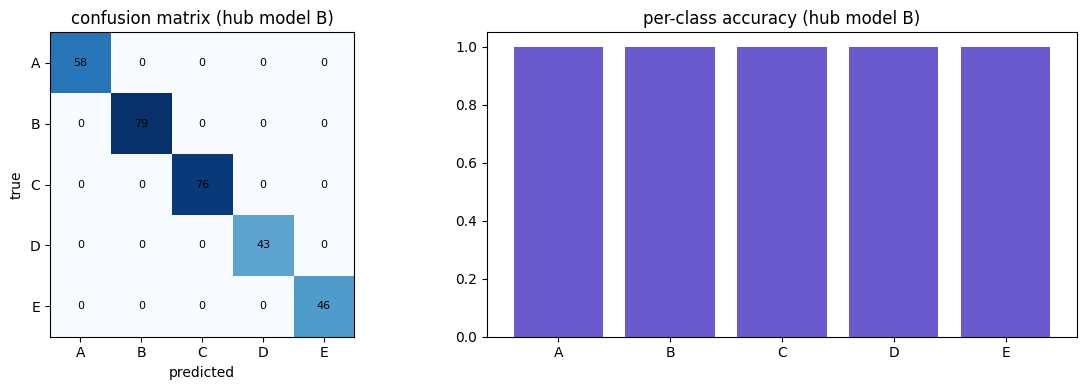

In [30]:
cm = confusion_matrix(y_va, infer_va_prob.argmax(axis=1))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].imshow(cm, cmap='Blues')
axes[0].set_xticks(range(len(label_enc.classes_)))
axes[0].set_xticklabels(label_enc.classes_)
axes[0].set_yticks(range(len(label_enc.classes_)))
axes[0].set_yticklabels(label_enc.classes_)
axes[0].set_xlabel('predicted')
axes[0].set_ylabel('true')
axes[0].set_title('confusion matrix (hub model B)')
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        axes[0].text(j, i, cm[i, j], ha='center', va='center', color='black', fontsize=8)

per_class_acc = cm.diagonal() / cm.sum(axis=1)
axes[1].bar(label_enc.classes_, per_class_acc, color='slateblue')
axes[1].set_title('per-class accuracy (hub model B)')
axes[1].set_ylim(0, 1.05)

plt.tight_layout()
plt.savefig('outputs/inference_confusion.png')
plt.show()

### Submission file + logging the inference run to wandb

In [31]:
write_submission(infer_te_prob, 'outputs/submission_hub_model_b.csv')

run_infer = wandb.init(
    project=wb_project,
    name=f'inference-hub-model-b-{hf_user}',
    group=hf_user,
    job_type='inference',
    config={'model': 'model_b', 'source': 'huggingface_hub', 'repo': repo_name},
)
run_infer.log({'infer_acc': infer_acc, 'infer_f1': infer_f1, 'infer_map3': infer_map3})
run_infer.log({'confusion_matrix': wandb.Image('outputs/inference_confusion.png')})
run_infer.summary['infer_acc'] = infer_acc
run_infer.summary['infer_map3'] = infer_map3
run_infer.finish()

print('-'*50)
print('INFERENCE SUMMARY (model pulled fresh from the hub)')
print('-'*50)
print('repo:', repo_name)
print('acc:', round(infer_acc, 4))
print('f1 (macro):', round(infer_f1, 4))
print('map3:', round(infer_map3, 4))
print('submission written to outputs/submission_hub_model_b.csv')

wrote outputs/submission_hub_model_b.csv


wandb: setting up run 75et1nha
wandb: Tracking run with wandb version 0.26.1
wandb: Run data is saved locally in /kaggle/working/wandb/run-20260730_182730-75et1nha
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run inference-hub-model-b-24f2005363
wandb: ⭐️ View project at https://wandb.ai/24f2005363-indian-institute-of-technology-madras/24f2005363-t22026
wandb: 🚀 View run at https://wandb.ai/24f2005363-indian-institute-of-technology-madras/24f2005363-t22026/runs/75et1nha
wandb: updating run metadata; uploading summary
wandb: uploading summary; uploading config.yaml; uploading wandb-metadata.json; uploading requirements.txt; uploading media/images/confusion_matrix_1_9820dda922890607a387.png (+ 1 more)
wandb: uploading summary
wandb: uploading history steps 0-1, summary
wandb: 
wandb: Run history:
wandb:  infer_acc ▁
wandb:   infer_f1 ▁
wandb: infer_map3 ▁
wandb: 
wandb: Run summary:
wandb:  infer_acc 1
wandb:   infer_f1 1
wandb: infer_map3 1
wandb: 
wandb: 🚀 View run in

--------------------------------------------------
INFERENCE SUMMARY (model pulled fresh from the hub)
--------------------------------------------------
repo: 24f2005363/mcq-answer-predictor-t22026
acc: 1.0
f1 (macro): 1.0
map3: 1.0
submission written to outputs/submission_hub_model_b.csv
